In [32]:
# TODO: replace this with databricks

%load_ext sql
%sql duckdb:///:memory:

%sql create or replace view V_SERIATIM as select * from read_parquet('../../mort_data/V_SERIATIM.parquet')

import sys
sys.path.insert(0, "../../")

The sql extension is already loaded. To reload it, use:
  %reload_ext sql


Running query in 'duckdb:///:memory:'

# Individual Life Data Analysis

This notebook provides an examples of how to use the **scaffolding tools** located in the lib directory to analyze real individual life data.  The data is derived from the SOA's public-use dataset (ILEC).

In this exercise you'll learn how to use a simple and powerful model for data exploration called a **Decision Tree**.

## Decision Trees

When the question is *why is the A/E or lift high or low?*, **Decision Trees** are the first tool you should reach for.  They provide:

 * Highly explainable outputs.

 * The ability to test different theories / variables as the "best" explanation.

 * Very powerful assistance with refinining GLMs.  Especially identifying missing interactions.


In [33]:
%%sql

select 
    OBSERVATION_YEAR,
    sum(CLAIM_COUNT)::int as CLAIM_COUNT,
    sum(EXPECTED_COUNT)::int AS EXPECTED_COUNT,
    round(sum(CLAIM_COUNT) / sum(EXPECTED_COUNT), 2) AS AE_RATIO
from V_SERIATIM 
group by OBSERVATION_YEAR
order by OBSERVATION_YEAR

Running query in 'duckdb:///:memory:'

OBSERVATION_YEAR,CLAIM_COUNT,EXPECTED_COUNT,AE_RATIO
2009,6366,6016,1.06
2010,4737,4548,1.04
2011,9121,8518,1.07
2012,5338,4850,1.1
2013,5779,5287,1.09
2014,6548,5980,1.1
2015,7404,6912,1.07
2016,8349,8096,1.03
2017,9496,9000,1.06
2018,8230,8283,0.99


### Building a decision tree

The **scaffolding library** makes building an interpretable decision tree very easy.

In [34]:
from src.lib.tree import PoissonDecisionTree


pdt = PoissonDecisionTree(
    actual_col="CLAIM_COUNT",
    offset_col="EXPECTED_COUNT"     # another word for the expected basis is an "offset" 
)

df_all_data = %sql select * from V_SERIATIM
df_all_data = df_all_data.DataFrame()

# don't forget to remove EXPOSURE or any other columns that are not 
# good explanations for A/E drivers (e.g. policy_id, etc.)
df_tree_data = df_all_data.drop(columns=["GROUP_ID", "OBS_ID", "POLICIES_EXPOSED", "FACE_AMOUNT_GRP_ORD"])

pdt.fit(df_tree_data)

pdt.print_tree()

Running query in 'duckdb:///:memory:'

root: ae=1.0575   y=71368
  - PREFERRED_CLASS < 0.5: ae=0.8185   y=17758
    - FACE_AMOUNT_GRP < 1.5: ae=1.0772   y=2768
      - ATTAINED_AGE < 61.5: ae=1.3270   y=690
      - ATTAINED_AGE >= 61.5: ae=1.0139   y=2078
    - FACE_AMOUNT_GRP >= 1.5: ae=0.7838   y=14990
      - ATTAINED_AGE < 82.5: ae=0.7530   y=11894
      - ATTAINED_AGE >= 82.5: ae=0.9300   y=3096
  - PREFERRED_CLASS >= 0.5: ae=1.1706   y=53610
    - ATTAINED_AGE < 56.5: ae=1.4861   y=6536
      - FACE_AMOUNT_GRP < 1.5: ae=2.2055   y=2781
      - FACE_AMOUNT_GRP >= 1.5: ae=1.1970   y=3755
    - ATTAINED_AGE >= 56.5: ae=1.1371   y=47074
      - DURATION < 2.5: ae=1.8703   y=1036
      - DURATION >= 2.5: ae=1.1272   y=46038


#### Understanding the output

``` root: ae=1.0575   y=71368 ```  -> Overall A/E = 1.0575%, there are 71,368 claims in this dataset (`y`)

**The most important variable is Preferred Class #2** since it occurs in the first level below the root.  

`  - PREFERRED_CLASS_2 < 0.5: ae=0.9144   y=24335`  <- first variable below root = most important

`    - ...`

`  - PREFERRED_CLASS_2 >= 0.5: ae=1.1506   y=47033`  <- ALSO part of the first variable below root = most important

`    - ...`

`PREFERRED_CLASS_2` is a catagorical variable that the decision tree has changed to a [one-hot encoding](https://www.datacamp.com/tutorial/one-hot-encoding-python-tutorial). Compare the above decision tree output  with the below table (made with SQL):

In [35]:
%%sql

select 
    case 
        when PREFERRED_CLASS = '2' then 'PREFERRED_CLASS = 2'
        else 'PREFERRED_CLASS_2 != 2'
    end as VARIABLE,
    sum(CLAIM_COUNT)::int as CLAIM_COUNT,
    sum(EXPECTED_COUNT)::int AS EXPECTED_COUNT,
    round(sum(CLAIM_COUNT) / sum(EXPECTED_COUNT), 2) AS AE_RATIO
from V_SERIATIM 
group by
    case 
        when PREFERRED_CLASS = '2' then 'PREFERRED_CLASS = 2'
        else 'PREFERRED_CLASS_2 != 2'
    end 
order by round(sum(CLAIM_COUNT) / sum(EXPECTED_COUNT), 2)


Running query in 'duckdb:///:memory:'

VARIABLE,CLAIM_COUNT,EXPECTED_COUNT,AE_RATIO
PREFERRED_CLASS_2 != 2,24335,26613,0.91
PREFERRED_CLASS = 2,47033,40877,1.15


#### Decision Tree Example Wrap-up

 * Decision trees are very good at **finding which variables explain A/E differences**.  They are credibility aware, so they will generally find credible splits.

 * **They are good at finding pockets of good / bad experience (data)**.  Don't stop there though!  Dig in, and look for other alternative answers!  In this example, Preferred #2 may be the pocket that's performing worst, but that's not the whole answer.

In short, decision trees help us find columns (variables) and rows (pockets of experience) to look at deeper.

#### Why decision trees work well for actuarial data

Decision trees address the **shortcomings of A/E ratios**.  

 * An A/E of 200% is meaningless unless we know the number of claims.  A 200% A/E is fine when 1 claim was expected, and we observed 2.  But a 200% A/E is __not__ fine when we see 500 claims vs. 250 expected.

 * We need at least one more number to interpret an A/E, either the expected or actual claims.

*Which of these deviations is the worst / most impactful?*

| Actual | Expected | A/E  | 
|--------|----------|------|
| 200    | 150      | 133% |
| 7,500  | 7,000    | 107% |

The top number is off by 50 claims, and the bottom is off by 500.  But the top number looks "worse" according to A/E.  Rather than using A/E, we need a measurement that **accounts for credibility**.  We can use the Poisson distribution to accomplish this.

Recreate the below table in Excel.  Copy the below formula into a fourth column called *Negative Log Likelihood (NLL)* .

```
=-1 * LOG(POISSON.DIST(A2,B2,FALSE))
```

| Actual | Expected | A/E  |  NLL | 
|--------|----------|------|-----------------|
| 200    | 150      | 133% |  4.82          |
| 7,500  | 7,000    | 107% |  9.91          |

Note that the larger NLL corresponds to the second row.  According to the Poisson distribution, this row has the more significant A/E difference.

 * Compare small and large value for actual and expected.  Note that the NLL reflects the credibility in actual and expected AND the difference between them.

### Key Takeaways

In simplest terms, **decision trees use NLL, rather than the A/E ratio** to find the largest errors in the predictions. It focuses on explaining the second row (with a 107% A/E) before looking at the 133% row, because of the much higher credibility.

Use them because they are **highly interpretable**. 

Use them for:

 1. Quick explorations of data to find the **most** predictive variables.
 
 2. Refining GLMs by adding interactions, or tweaking knots (for splines).


### XGBoost

XGboost is a very powerful modeling approach, but **it is prone to overfitting**.  To understand why, we need to understand how it works:

 1. XGboost fits a single decision tree to the data
 2. It checks the predictions of the decision tree vs. the actuals (target variable), identifying records in the training data where the decision tree performs the worst. 
 3. It attempts to "fix" these mispredictions by fitting a second tree to the mispredictions. We are creating a "chain" of decision trees that fix the errors made by the previous tree.
 4. Repeat this process an arbitrary number of times.

Step #4 is where we run into problems.  How many times do we need to fix the mispredictions?  If we go too far, and we are prefectly predicting (or memorizing) the training data, that is overfitting.

There are a variety of technical approaches, like **early stopping and hyper-parameter tuning**, that can be used to allieviate the problem.  XGBoost has built-in support for early-stopping, but we need to use a library like `hyperopt` (obsolete) or `optuna` (preferred) that has a bit of a learning curve.

#### Inferential Modeling with XGBoost

XGBoost is not just a powerful predictive model, it is a powerful data analysis tool when combined with [SHAP](https://shap.readthedocs.io/en/latest/example_notebooks/overviews/An%20introduction%20to%20explainable%20AI%20with%20Shapley%20values.html).  Here are the types of questions that we can answer using XGBoost + SHAP:

 * What are the top-n most important features in the data?
 * For continuous variables, what is the shape of the relationship between the predictor (e.g. age) and the target variable (e.g. claims)?
 * When we are evaluating features, what is the "best-case" performance that we could get using the same set of features in a GLM?

Let's look at an example.  Note that we are using **early stopping** to prevent drastic overfitting, but we are **not tuning hyperparameters** (e.g., with optuna).  Early stopping **requires a train-test split**, and we should be thoughtful about how we do this.

 1. First we will draw a random 80% sample from the data.  This is the simplest approach, but not usually the best approach.
 2. Next, we will draw a **stratified** sample from the data on `Observation_Year`, i.e., the year that the exposures and claims occurred. 
 3. Last, we will use **future `Observation_Year`** records in the hold-out set. This is one of the most conservative approaches we can take to ensure that we aren't overfitting, especially with mortality.

In [36]:
# randomly sample 
df_training_data = df_tree_data.sample(frac=0.8, random_state=42)
df_testing_data = df_tree_data.drop(df_training_data.index)

df_training_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1772867 entries, 893397 to 2068981
Data columns (total 13 columns):
 #   Column                       Dtype  
---  ------                       -----  
 0   OBSERVATION_YEAR             int32  
 1   GENDER                       object 
 2   SMOKER_STATUS                object 
 3   ISSUE_AGE                    int32  
 4   DURATION                     int32  
 5   ATTAINED_AGE                 int32  
 6   FACE_AMOUNT_GRP              object 
 7   ISSUE_YEAR                   int32  
 8   NUMBER_OF_PREFERRED_CLASSES  object 
 9   PREFERRED_CLASS              object 
 10  SELECT_ULTIMATE_INDICATOR    object 
 11  EXPECTED_COUNT               float64
 12  CLAIM_COUNT                  float64
dtypes: float64(2), int32(5), object(6)
memory usage: 155.5+ MB


#### Dealing with categorical predictors

XGBoost can be "smart" about **categorical predictors** if you tell it to be.  Rather than creating a new column for each level (value) in a categorical, we can integer encode it.  This allows it to say when the `face_amount` is "$100K-$249K or $250K-$499K" then a certain adjustment is needed, i.e., it can group categorical values when it makes sense.

But `face_amount` is a special type of a categorical, called an `ordinal`, so there is a second option that we can experiment with.  We can convert the face amounts to integers, so that the lowest face amount band (e.g. $1-$25K) corresponds to the integer 1, and the highest ($2.5M+) corresponds to 8, assuming there are 8 total face bands.

 * We should treat `face_amount` as ordinal if we want to avoid unintuitive predictions. Actuaries generally think that mortality should get better at higher face amounts.  Treating `face_amount` as an ordinal makes it a bit easier to enforce this reasoning on the model.  There are some more details to add, but for now, just know that it's a possible approach when that behavior is desired.

In [37]:
# helper function to make the categorical columns
def make_categorical_mapper(df):
    category_levels = {}
    for col in df.select_dtypes(include=['object', 'string']).columns:
        category_levels[col] = list(df[col].dropna().unique())

    def apply_categorical_levels(input_df):
        output_df = input_df.copy()
        for col, levels in category_levels.items():
            if col in output_df.columns:
                output_df[col] = output_df[col].astype('category').cat.set_categories(levels)
        return output_df

    return apply_categorical_levels

apply_categorical_levels = make_categorical_mapper(df_training_data)
df_training_data = apply_categorical_levels(df_training_data)
df_testing_data = apply_categorical_levels(df_testing_data)

df_training_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1772867 entries, 893397 to 2068981
Data columns (total 13 columns):
 #   Column                       Dtype   
---  ------                       -----   
 0   OBSERVATION_YEAR             int32   
 1   GENDER                       category
 2   SMOKER_STATUS                category
 3   ISSUE_AGE                    int32   
 4   DURATION                     int32   
 5   ATTAINED_AGE                 int32   
 6   FACE_AMOUNT_GRP              category
 7   ISSUE_YEAR                   int32   
 8   NUMBER_OF_PREFERRED_CLASSES  category
 9   PREFERRED_CLASS              category
 10  SELECT_ULTIMATE_INDICATOR    category
 11  EXPECTED_COUNT               float64 
 12  CLAIM_COUNT                  float64 
dtypes: category(6), float64(2), int32(5)
memory usage: 84.5 MB


#### Training the xgboost model

XGBoost can make use of an offset variable, but it calls this a `base_margin`.  It can use Tweedie and Poisson loss functions, making it well suited to insurance problems.  We have to select hyperparameters that control the fitting, we'll use some reasonable default values here, but these should definetly be tuned using `optuna` when we are actually building models.

In [38]:
import xgboost as xgb, numpy as np

def make_dmatrix(df, response_var, offset_var):
    X = df.drop(columns=[response_var, offset_var])
    y = df[response_var]
    offset = np.log(df[offset_var])

    return (
        X,
        y,
        offset,
        # XGBoost needs a special data structure called a DMatrix, which is optimized for training.
        xgb.DMatrix(
            X,
            label=y,
            base_margin=offset,
            # must set this to "true" to use categorical handling!
            enable_categorical=True,
        ),
    )

# prepare the data for training, xgb_train and xgb_test contain X, y, and offset for each dataset.  It is a special object,
# called an xgboost DMatrix (Dense Matrix), used by xgboost for training.
X_train, y_train, offset_train, xgb_train = make_dmatrix(df_training_data, response_var="CLAIM_COUNT", offset_var="EXPECTED_COUNT")
X_test, y_test, offset_test, xgb_test = make_dmatrix(df_testing_data, response_var="CLAIM_COUNT", offset_var="EXPECTED_COUNT")


In [39]:
# early-stopping will prevent us from reaching this, but we should set an upper-limit
XGB_MAX_TREES = 1000

xgb_params = {
    "objective": "count:poisson",
    "tree_method": "hist",
    # these are the main hyperparameters, but there are MANY more not listed here.
    "eta": 0.1,
    "gamma": 1,
    "max_depth": 3,
    "subsample": 0.8,
    "colsample_bytree":0.75
}

# perform training
xgb_model = xgb.train(
    xgb_params,
    xgb_train,
    XGB_MAX_TREES,
    evals=[(xgb_test, "test")],
    verbose_eval=25, # print training progress every 25 trees
    early_stopping_rounds=10,
)

[0]	test-poisson-nloglik:0.09951
[25]	test-poisson-nloglik:0.09874
[50]	test-poisson-nloglik:0.09859
[75]	test-poisson-nloglik:0.09851
[100]	test-poisson-nloglik:0.09848
[125]	test-poisson-nloglik:0.09846
[150]	test-poisson-nloglik:0.09844
[175]	test-poisson-nloglik:0.09843
[200]	test-poisson-nloglik:0.09842
[225]	test-poisson-nloglik:0.09841
[246]	test-poisson-nloglik:0.09841


#### Understanding the XGBoost Model

 * Feature importance is the first step to understanding our model. There are many ways to calculate this, but the most natural one with xgboost is **gain**. It can be thought of as "how high up in my decision tree does this occur?".  The more gain, the better the feature is for getting our A/E closer to 100%.
 
 * The below code shows the feature importance based on **total_gain**.  A second alternative is to use the **average gain**.


In [40]:
import pandas as pd

# one way of calculating feature importance
pd.DataFrame(
    xgb_model.get_score(importance_type="total_gain").items(), 
    columns=["feature", "total_gain"]
).sort_values(by="total_gain", ascending=False)

,feature,total_gain
9,PREFERRED_CLASS,5834.859375
6,FACE_AMOUNT_GRP,5072.072266
5,ATTAINED_AGE,3400.341064
4,DURATION,1798.106323
3,ISSUE_AGE,1260.333496
7,ISSUE_YEAR,1069.080444
0,OBSERVATION_YEAR,553.653198
10,SELECT_ULTIMATE_INDICATOR,508.355743
2,SMOKER_STATUS,463.507629
8,NUMBER_OF_PREFERRED_CLASSES,391.355133


#### Which version of gain should I use for feature importance?

The short answer: both.

Imagine you are building a GLM and have fit the model output with xgboost to try and make it better:

 * Total gain tells you how important overall this feature is.  A feature with high total gain, but low average gain, probably doesn't need an interaction.

 * Likewise a feature with low total gain and high average gain is likely a good candidate for interactions.

Both these statements are practical rules-of-thumb, but not mathematical certainties.

In [41]:
# an alternative way
pd.DataFrame(
    xgb_model.get_score(importance_type="gain").items(), 
    columns=["feature", "average_gain"]
).sort_values(by="average_gain", ascending=False)

,feature,average_gain
9,PREFERRED_CLASS,42.903378
10,SELECT_ULTIMATE_INDICATOR,39.104286
6,FACE_AMOUNT_GRP,20.369768
5,ATTAINED_AGE,11.526580
4,DURATION,8.728671
8,NUMBER_OF_PREFERRED_CLASSES,7.115548
2,SMOKER_STATUS,6.528276
1,GENDER,5.566622
7,ISSUE_YEAR,5.372263
3,ISSUE_AGE,5.041334


In [42]:
# manually calculate the total gain
(xgb_model.trees_to_dataframe()
.groupby("Feature")
.agg({"Gain": "sum"})
).sort_values(by="Gain", ascending=False)

,Gain
Feature,
PREFERRED_CLASS,5834.862178
FACE_AMOUNT_GRP,5072.073110
ATTAINED_AGE,3400.341459
DURATION,1798.106294
ISSUE_AGE,1260.333682
ISSUE_YEAR,1069.080076
OBSERVATION_YEAR,553.652951
SELECT_ULTIMATE_INDICATOR,508.355754
SMOKER_STATUS,463.507628


#### SHAP

SHAP (short for shapely values) is a general purpose method for understanding "black-box" models.  It's most computationally efficient on tree-based models like xgboost.  It can be used both to understand the models general behavior as well as individual predictions.

 * Because SHAP is computationally difficult we have to run it on a sample.  If the sample is biased, we can see misleading results!  Try to use all the data when possible, OR carefully choose your sample (very situation specific).

 * A general rule of thumb when choosing a sample for a 2d dependency plot is to use the x and y axis (see below).

In [43]:
import shap as shp

shp_explainer = shp.TreeExplainer(xgb_model)

In [44]:
# Required categorical columns for this summary.
face_col = "FACE_AMOUNT_GRP"
preferred_col = "PREFERRED_CLASS"

missing_cols = [c for c in [face_col, preferred_col] if c not in X_train.columns]
if missing_cols:
    raise ValueError(f"Missing required columns in X_train: {missing_cols}")

# XGBoost native SHAP contributions (pred_contribs) with categorical support.
# This avoids the shap.TreeExplainer categorical DMatrix issue.
xgb_train_for_shap = xgb.DMatrix(X_train, enable_categorical=True)
contrib = xgb_model.predict(xgb_train_for_shap, pred_contribs=True)

# Last column is the model bias term; remove it for feature-level summaries.
feature_contrib = pd.DataFrame(
    contrib[:, :-1],
    columns=X_train.columns,
    index=X_train.index,
)

# Build grouped table by both categoricals.
shap_table = X_train[[face_col, preferred_col]].copy()
shap_table["shap_face_amount_grp"] = feature_contrib[face_col].values
shap_table["shap_preferred_class"] = feature_contrib[preferred_col].values
shap_table["shap_total_abs"] = feature_contrib.abs().sum(axis=1).values

shap_summary = (
    shap_table.groupby([face_col, preferred_col], as_index=False)
    .agg(
        exposure_rows=(face_col, "size"),
        avg_shap_face_amount_grp=("shap_face_amount_grp", "mean"),
        avg_shap_preferred_class=("shap_preferred_class", "mean"),
        avg_total_abs_shap=("shap_total_abs", "mean"),
    )
    .sort_values([face_col, preferred_col])
    .reset_index(drop=True)
)

shap_summary

/tmp/ipykernel_30150/2234174468.py:28: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.


,FACE_AMOUNT_GRP,PREFERRED_CLASS,exposure_rows,avg_shap_face_amount_grp,avg_shap_preferred_class,avg_total_abs_shap
0,G. 1000000-2499999,1,82593,-0.251091,-0.266442,0.810274
1,G. 1000000-2499999,2,67820,-0.232716,0.093407,0.655782
2,G. 1000000-2499999,3,23396,-0.226950,0.227208,0.851999
3,G. 1000000-2499999,4,3481,-0.283157,0.221539,0.988052
4,E. 250000-499999,1,117448,-0.239573,-0.257802,0.779602
5,E. 250000-499999,2,109707,-0.223038,0.092604,0.632543
6,E. 250000-499999,3,35094,-0.215645,0.221662,0.809664
7,E. 250000-499999,4,7642,-0.242852,0.234343,0.964859
8,A. 1-24999,1,57738,0.313776,-0.205141,0.886893
9,A. 1-24999,2,94821,0.248336,0.075151,0.741038


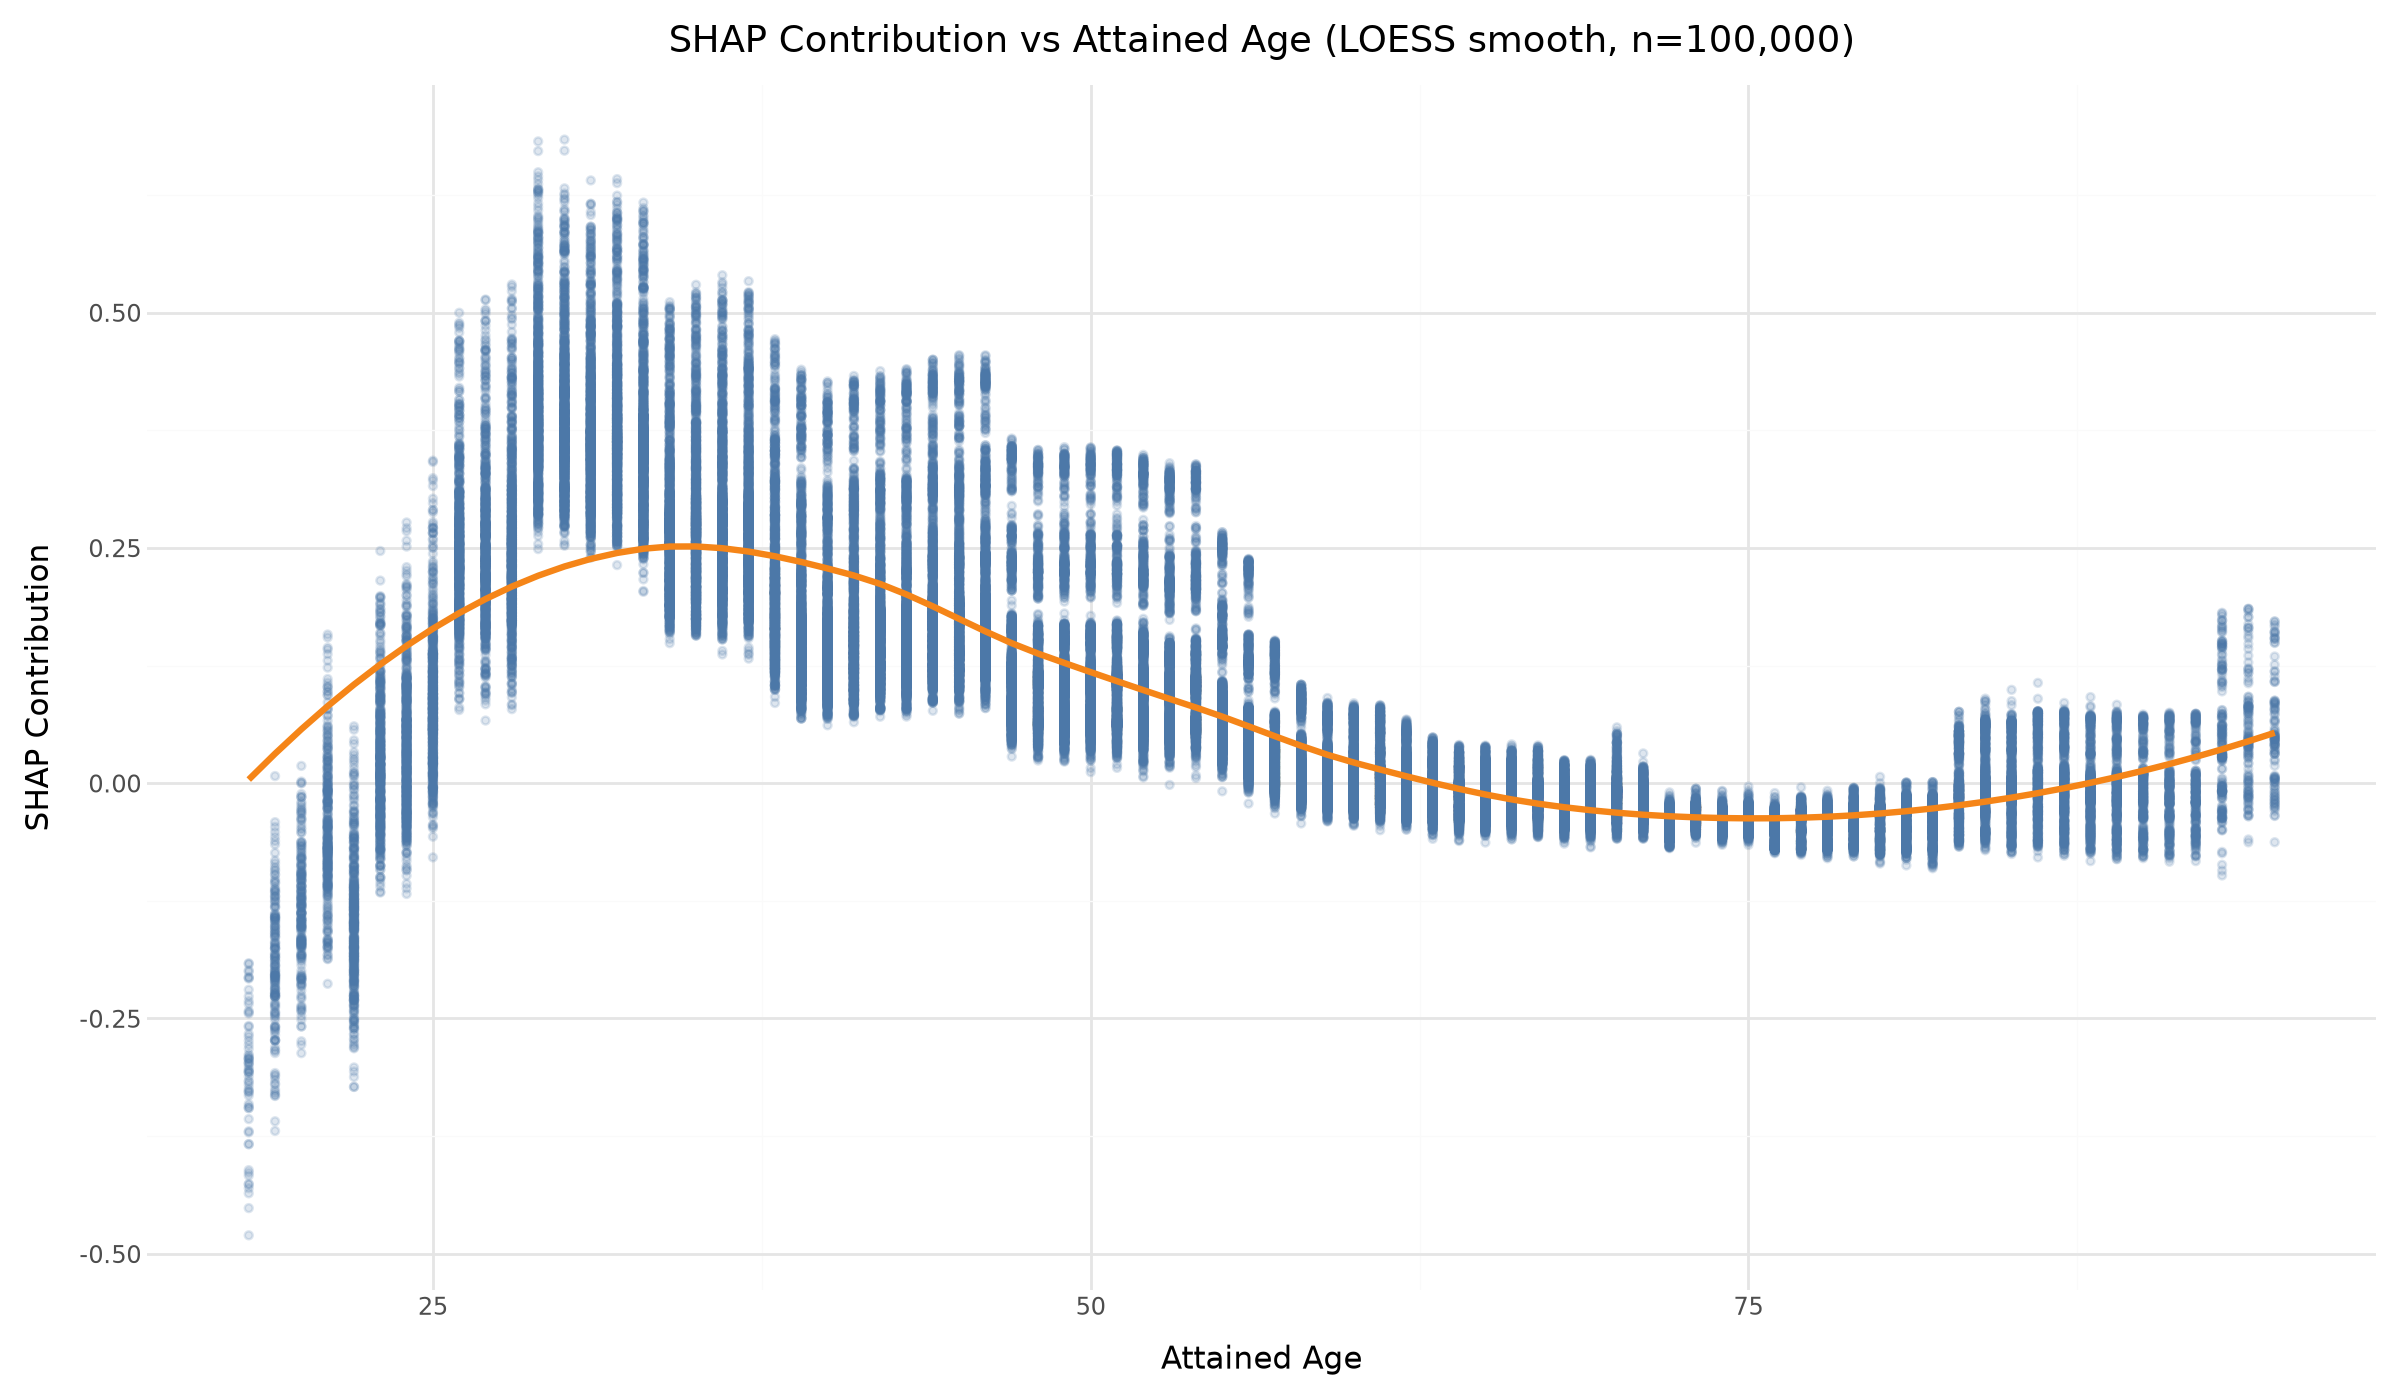

In [47]:
import pandas as pd
from plotnine import ggplot, aes, geom_point, geom_smooth, labs, theme_minimal, theme, element_text

# Locate attained age column.
attained_age_candidates = ["ATTAINED_AGE", "AGE_ATTAINED", "ATT_AGE"]
age_col = next((c for c in attained_age_candidates if c in X_train.columns), None)
if age_col is None:
    raise ValueError(f"Attained age column not found in X_train. Checked: {attained_age_candidates}")

# Random sample for SHAP plotting (cap at 100,000 rows).
sample_n = min(100_000, len(X_train))
X_plot = X_train.sample(n=sample_n, random_state=42, replace=False)

# Get SHAP contributions from XGBoost natively (handles categorical data via DMatrix).
xgb_plot_for_shap = xgb.DMatrix(X_plot, enable_categorical=True)
contrib = xgb_model.predict(xgb_plot_for_shap, pred_contribs=True)
feature_contrib = pd.DataFrame(
    contrib[:, :-1],
    columns=X_plot.columns,
    index=X_plot.index,
)

plot_df = pd.DataFrame({
    "attained_age": pd.to_numeric(X_plot[age_col], errors="coerce"),
    "shap_contribution": feature_contrib[age_col],
}).dropna()

# Prefer loess if available; otherwise use lowess, then lm as a final fallback.
smooth_method = "lm"
try:
    from skmisc.loess import loess  # noqa: F401
    smooth_method = "loess"
except Exception:
    try:
        import statsmodels.api as sm  # noqa: F401
        smooth_method = "lowess"
    except Exception:
        smooth_method = "lm"

(
    ggplot(plot_df, aes(x="attained_age", y="shap_contribution"))
    + geom_point(alpha=0.18, size=1.1, color="#4C78A8")
    + geom_smooth(method=smooth_method, se=False, color="#F58518", size=1.3)
    + labs(
        title=f"SHAP Contribution vs Attained Age ({smooth_method.upper()} smooth, n={sample_n:,})",
        x="Attained Age",
        y="SHAP Contribution",
    )
    + theme_minimal()
    + theme(
        figure_size=(12, 7),
        axis_text_x=element_text(rotation=0, hjust=0.5),
    )
)

#### Appendix: XGboost training vs. gain

I don't know if this is useful, but I thought it was interesting.

We can track the model's investigation of different features by tracking their gain vs. the number of trees we've built (iterations).  

/tmp/ipykernel_30150/2872004088.py:68: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
/tmp/ipykernel_30150/2872004088.py:69: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.


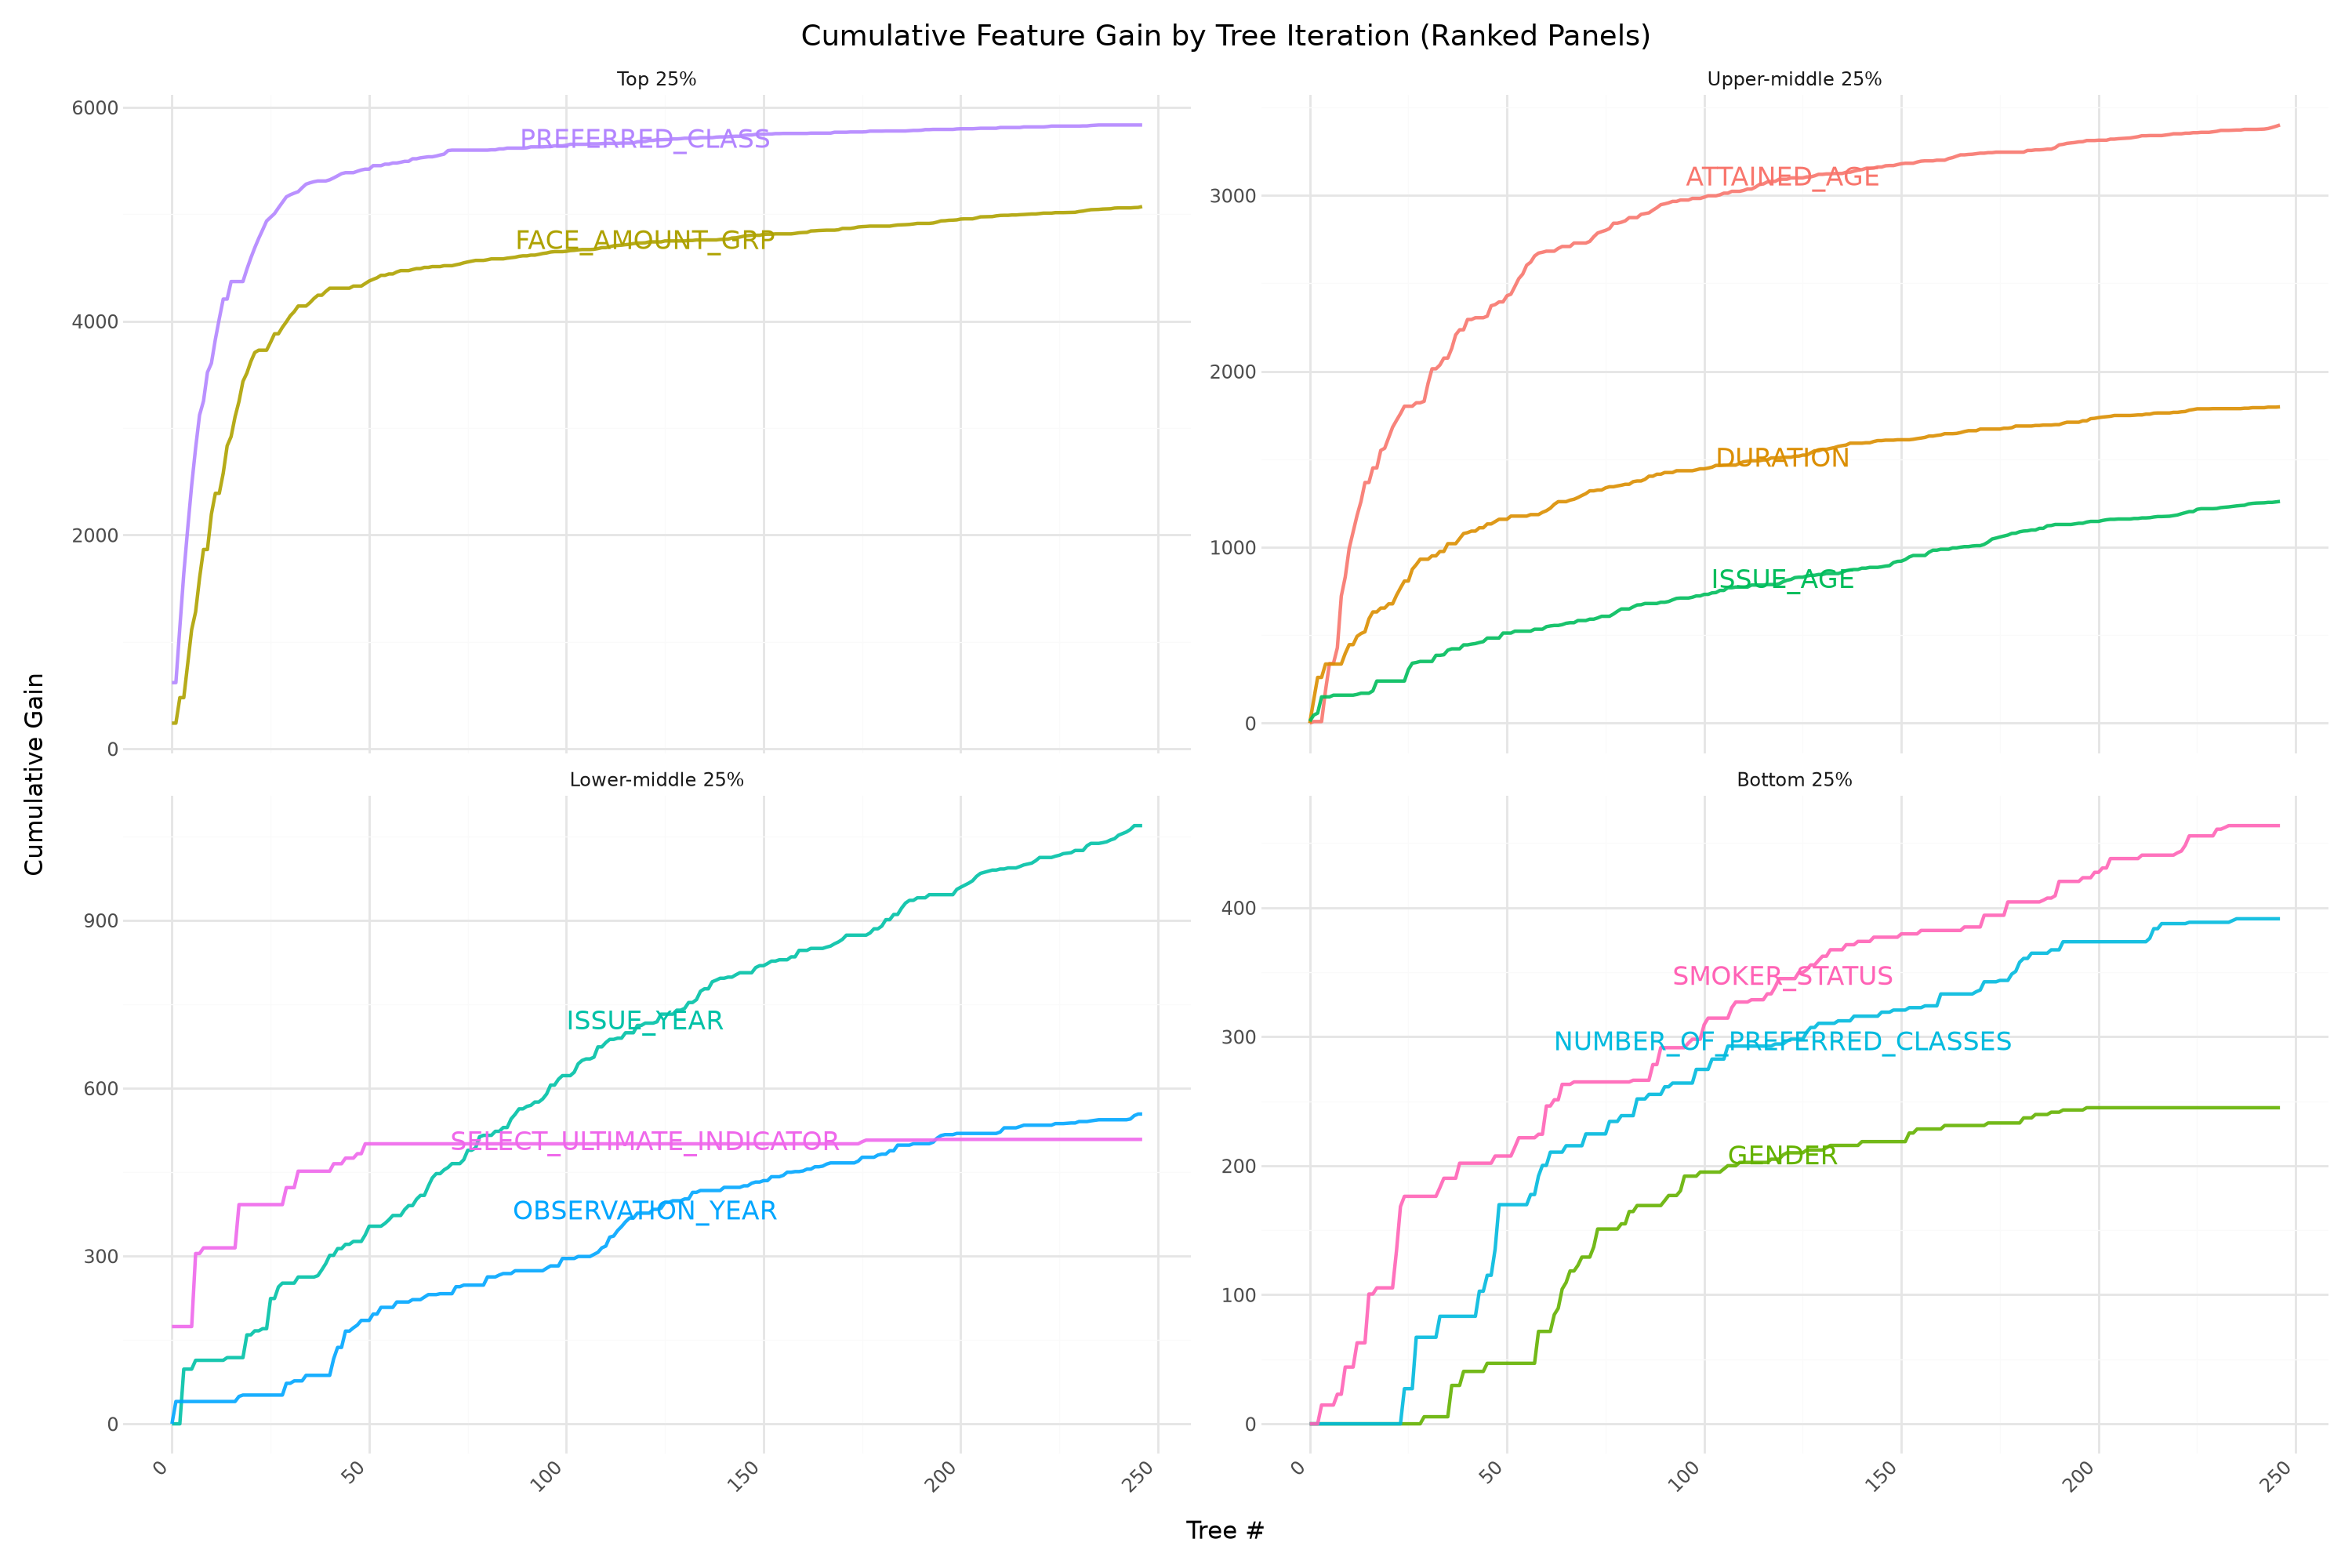

In [46]:
import pandas as pd
from plotnine import (
    ggplot,
    aes,
    geom_line,
    geom_text,
    labs,
    theme_minimal,
    theme,
    element_text,
    facet_wrap,
)

# Pull split-level gain data and keep only real split features (exclude leaf rows).
trees_df = xgb_model.trees_to_dataframe()
feature_gain_by_tree = (
    trees_df.loc[trees_df["Feature"].ne("Leaf"), ["Tree", "Feature", "Gain"]]
    .groupby(["Tree", "Feature"], as_index=False)["Gain"]
    .sum()
    .sort_values(["Feature", "Tree"])
    .reset_index(drop=True)
)

# Build a complete Tree x Feature grid so lines continue across trees with zero added gain.
all_trees = pd.Index(sorted(feature_gain_by_tree["Tree"].unique()), name="Tree")
all_features = pd.Index(sorted(feature_gain_by_tree["Feature"].unique()), name="Feature")
feature_tree_grid = pd.MultiIndex.from_product([all_trees, all_features], names=["Tree", "Feature"]).to_frame(index=False)

feature_gain_complete = (
    feature_tree_grid
    .merge(feature_gain_by_tree, on=["Tree", "Feature"], how="left")
    .fillna({"Gain": 0.0})
    .sort_values(["Feature", "Tree"])
    .reset_index(drop=True)
)

feature_gain_complete["cumulative_gain"] = feature_gain_complete.groupby("Feature")["Gain"].cumsum()

# Rank features by final cumulative gain, then split into 4 equal-count panels.
feature_rank = (
    feature_gain_complete.groupby("Feature", as_index=False)["cumulative_gain"]
    .max()
    .rename(columns={"cumulative_gain": "final_cumulative_gain"})
    .sort_values("final_cumulative_gain", ascending=False)
    .reset_index(drop=True)
)
feature_rank["rank"] = feature_rank.index + 1
feature_rank["percentile"] = feature_rank["rank"] / len(feature_rank)

def assign_panel(p):
    if p <= 0.25:
        return "Top 25%"
    if p <= 0.50:
        return "Upper-middle 25%"
    if p <= 0.75:
        return "Lower-middle 25%"
    return "Bottom 25%"

feature_rank["panel"] = feature_rank["percentile"].map(assign_panel)
panel_order = ["Top 25%", "Upper-middle 25%", "Lower-middle 25%", "Bottom 25%"]
feature_rank["panel"] = pd.Categorical(feature_rank["panel"], categories=panel_order, ordered=True)

plot_df = feature_gain_complete.merge(feature_rank[["Feature", "panel"]], on="Feature", how="left")

# Label each feature at the midpoint tree for that feature's trajectory inside each panel.
label_df = (
    plot_df.sort_values(["panel", "Feature", "Tree"])
    .groupby(["panel", "Feature"], as_index=False, group_keys=False)
    .apply(lambda g: g.iloc[[len(g) // 2]])
    .reset_index(drop=True)
)

(
    ggplot(plot_df, aes(x="Tree", y="cumulative_gain", color="Feature"))
    + geom_line(size=0.9, alpha=0.9)
    + geom_text(
        data=label_df,
        mapping=aes(label="Feature"),
        ha="center",
        va="center",
        size=12,
        show_legend=False,
    )
    + facet_wrap("~panel", ncol=2, scales="free_y")
    + labs(
        title="Cumulative Feature Gain by Tree Iteration (Ranked Panels)",
        x="Tree #",
        y="Cumulative Gain",
    )
    + theme_minimal()
    + theme(
        figure_size=(15, 10),
        axis_text_x=element_text(rotation=45, hjust=1),
        legend_position="none",
    )
)